# 📘 Notebook 11: Automatic Hyperparameter Search with Optuna

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab (the first cell installs Optuna if needed).
>
> ⏱️ **Training time and limitations.** About **fifteen minutes** on an ordinary processor. Each search tries 40 settings with short trainings (8 epochs); real searches use more trials and longer runs, often on several GPUs in parallel. With few trials, the comparison between search methods is noisy: one search can be lucky. The final model is evaluated **once** on the test set, at the very end.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain **grid search**, **random search** and **Bayesian optimisation** (Optuna's TPE sampler)
- Explain why random search beats grid search when only some hyperparameters matter
- Write an Optuna **objective** that chooses the number of **layers**, **neurons**, **activation**, **learning rate**, **dropout** and **batch size**
- Use **pruning** to stop hopeless trials early
- Read Optuna's results: the best trial, the history and the **importance** of each hyperparameter
- Evaluate the chosen model **honestly** on the test set

> **Prerequisites:** Notebooks [01](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/01_what_is_a_hyperparameter.ipynb) to [10](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/10_batchnorm_and_schedules.ipynb) of this course.
>
> 🔭 **Why this notebook matters:** after ten notebooks of tuning by hand, we let the computer do it. Optuna is a free library that searches hyperparameters intelligently: you describe **what** may vary and **how** to score a setting, and it decides **which** settings to try, learning from every result. It is widely used in research and industry, and works with any model, not just neural networks.

## 1. The papers

> 📄 Random search: J. Bergstra and Y. Bengio, [*Random Search for Hyper-Parameter Optimization*](https://jmlr.org/papers/v13/bergstra12a.html), JMLR 13, 2012.
>
> 📄 TPE: J. Bergstra, R. Bardenet, Y. Bengio and B. Kégl, [*Algorithms for Hyper-Parameter Optimization*](https://papers.nips.cc/paper/2011/hash/86e8f7ab32cfd12577bc2619bc635690-Abstract.html), NeurIPS 2011.
>
> 📄 Optuna: T. Akiba, S. Sano, T. Yanase, T. Ohta and M. Koyama, [*Optuna: A Next-generation Hyperparameter Optimization Framework*](https://arxiv.org/abs/1907.10902), KDD 2019.

### Intuition first
- **Grid search** tries every combination of a few values per hyperparameter. With 6 hyperparameters and 4 values each, that is 4,096 trainings, and most of them vary things that hardly matter.
- **Random search** draws settings at random. With the same budget it tries **many more distinct values** of each hyperparameter, so it finds good values of the few that matter much faster.
- **Bayesian optimisation** (here Optuna's **TPE**, Tree-structured Parzen Estimator) also starts at random, then models which regions gave good results and samples more there. It spends the budget where it is likely to pay off.

In [ ]:
%pip install -q optuna

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


In [2]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
print("Optuna", optuna.__version__)

Optuna 4.1.0


## 2. The search space and the objective

The **objective** is a function that receives a `trial`, asks it for a value of each hyperparameter, trains a network and returns the score to maximise: here the validation accuracy. `trial.suggest_...` is how Optuna proposes values; `log=True` searches by factors, as Notebook 03 recommended for learning rates.

In [3]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "gelu": nn.GELU, "silu": nn.SiLU}

def build(trial):
    layers = trial.suggest_int("layers", 1, 4)
    width = trial.suggest_int("neurons", 16, 1024, log=True)
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS))
    dropout = trial.suggest_float("dropout", 0.0, 0.5)
    return make_mlp(hidden=(width,) * layers, activation=ACTIVATIONS[activation], dropout=dropout)

def objective(trial, epochs=8):
    model = build(trial)
    lr = trial.suggest_float("lr", 1e-5, 1e-1, log=True)
    batch = trial.suggest_categorical("batch", [32, 64, 128, 256, 512])
    torch.manual_seed(trial.number)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X_train))
        for i in range(0, len(X_train), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        val = accuracy(model, X_val, y_val)
        trial.report(val, epoch)              # tell Optuna how the trial is going
        if trial.should_prune():              # and let it stop hopeless trials early
            raise optuna.TrialPruned()
    return val

## 3. Random search against TPE

Two searches with the same budget of 40 trials: one with Optuna's random sampler, one with TPE and the **median pruner** (which stops a trial whose validation accuracy, after a few epochs, is worse than the median of earlier trials at the same epoch).

random search  : best val acc 0.8612 after 472 s, 0 of 40 trials pruned


TPE + pruning  : best val acc 0.8612 after 283 s, 19 of 40 trials pruned


random search  : mean val acc of the finished trials among the last 20: 0.6630
TPE + pruning  : mean val acc of the finished trials among the last 20: 0.8520


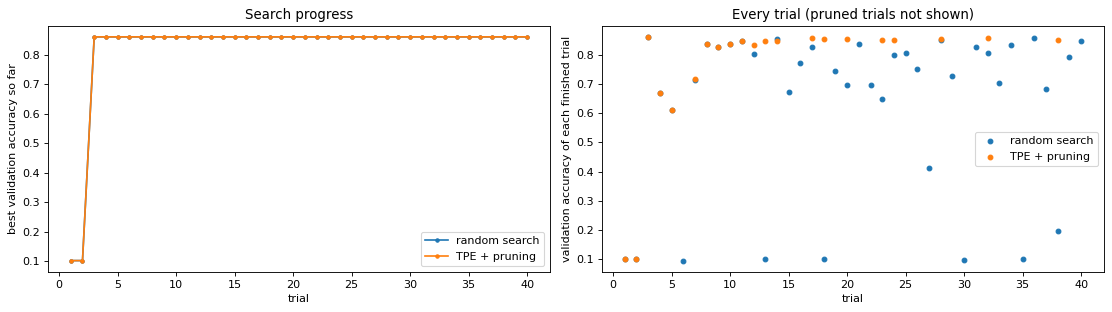

In [4]:
searches = {}
for name, sampler, pruner in [("random search", optuna.samplers.RandomSampler(seed=0), optuna.pruners.NopPruner()),
                              ("TPE + pruning", optuna.samplers.TPESampler(seed=0), optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2))]:
    study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)
    start = time.time()
    study.optimize(objective, n_trials=40)
    searches[name] = study
    pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
    print(f"{name:15s}: best val acc {study.best_value:.4f} after {time.time() - start:.0f} s, {pruned} of 40 trials pruned")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, study in searches.items():
    values = pd.Series([t.value if t.state == optuna.trial.TrialState.COMPLETE else np.nan for t in study.trials], index=range(1, 41))
    axes[0].plot(values.index, values.ffill().cummax(), marker="o", ms=3, label=name)
    axes[1].scatter(values.index, values, s=18, label=name)
    print(f"{name:15s}: mean val acc of the finished trials among the last 20: {values.iloc[20:].mean():.4f}")
axes[0].set_ylabel("best validation accuracy so far"); axes[0].set_title("Search progress")
axes[1].set_ylabel("validation accuracy of each finished trial"); axes[1].set_title("Every trial (pruned trials not shown)")
for ax in axes:
    ax.set_xlabel("trial"); ax.legend()
plt.tight_layout()
plt.show()

**What we see.** Both searches found the **same** best setting, **86.1%**, at the **same** trial (the third). This is not a coincidence: TPE begins with 10 random trials to learn from, and with the same seed they are exactly the trials of the random search. One of them happened to be very good, and neither search beat it in the remaining 37 trials. With a budget this small, the **best** value says little about the method.

The right panel shows what the methods actually did:
- **Random search** keeps scattering trials over the whole space to the end: many land at 60 to 80%, and several at **10%** (learning rates so large that training diverged). The finished trials among the last 20 average **66.3%**.
- **TPE** learns from the first trials and concentrates on the good region: after trial 10 almost every finished trial is between 83 and 86%, an average of **85.2%** over the last 20. (Part of that average comes from pruning, which stops poor trials before they finish, so they are not plotted.)
- **Pruning** stopped **19 of 40** trials after a few epochs and cut the search time from 472 to **283 seconds**, about 40% less.

So TPE did not find a better maximum here, but it spent its budget far more wisely; with a larger space or more trials, that is what finds better settings.

In [5]:
best = searches["TPE + pruning"].best_trial
print("best setting found by TPE:")
for k, v in best.params.items():
    print(f"  {k:10s} {v:.5g}" if isinstance(v, float) else f"  {k:10s} {v}")
trials = searches["TPE + pruning"].trials_dataframe(attrs=("number", "value", "params", "state"))
trials.sort_values("value", ascending=False).head(8).round(4)

best setting found by TPE:
  layers     1
  neurons    812
  activation silu
  dropout    0.22808
  lr         0.0018782
  batch      512


,number,value,params_activation,params_batch,params_dropout,params_layers,params_lr,params_neurons,state
2,2,0.861,silu,512,0.228,1,0.002,812,COMPLETE
16,16,0.858,relu,512,0.155,2,0.007,269,COMPLETE
31,31,0.856,relu,128,0.155,2,0.002,81,COMPLETE
17,17,0.854,relu,512,0.173,2,0.009,151,COMPLETE
19,19,0.853,relu,128,0.174,2,0.002,91,COMPLETE
27,27,0.852,relu,512,0.122,2,0.006,224,COMPLETE
23,23,0.852,relu,512,0.166,2,0.001,376,COMPLETE
22,22,0.850,relu,512,0.178,2,0.010,133,COMPLETE


**What we see.** The winning setting is **one hidden layer of 812 SiLU neurons**, dropout 0.23, learning rate 0.0019, batch 512. The other top trials, chosen by TPE after it had learned, share a pattern: two layers, ReLU, dropout between 0.12 and 0.18, learning rate between 0.001 and 0.01 and mostly batch 512, with widths anywhere from 81 to 376. The same accuracy (85 to 86%) is reached by quite different networks, which agrees with Notebooks 05 and 06: on this problem, width and activation hardly matter once the learning rate is right.

## 4. Which hyperparameters mattered?

Optuna estimates the **importance** of each hyperparameter from the finished trials (by how much of the variation in the score each one explains).

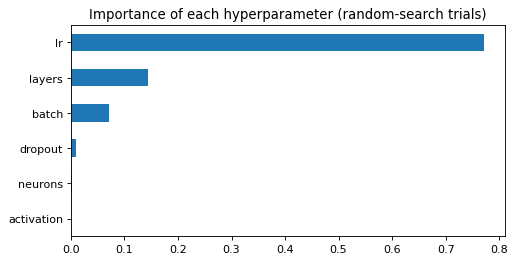

,importance
lr,0.772
layers,0.143
batch,0.072
dropout,0.010
neurons,0.003
activation,0.001


In [6]:
importance = optuna.importance.get_param_importances(searches["random search"])
plt.figure(figsize=(7, 3.5))
pd.Series(importance).sort_values().plot.barh()
plt.title("Importance of each hyperparameter (random-search trials)")
plt.show()
pd.Series(importance).round(3).to_frame("importance")

**What we see.** The **learning rate** explains about **77%** of the variation between trials, the number of **layers** 14% and the **batch size** 7%; dropout, width and activation together less than 2%. This is the course in one chart: Notebook 03 called the learning rate "the hyperparameter that matters most", and the search confirms it independently. (Importances are estimated with a small random forest, so they change a little from run to run; the order is what matters.) The practical lesson is to **spend tuning effort on the learning rate first**, and to fix the unimportant hyperparameters at sensible values.

## 5. The honest final step

The best validation score is the winner of 40 contests and therefore optimistic (Notebook 01). We retrain the chosen setting for longer with early stopping, then evaluate it **once** on the test set, and compare with the default network of Notebook 01.

In [7]:
import copy
def final_train(params, max_epochs=60, patience=5, seed=0):
    torch.manual_seed(seed)
    model = make_mlp(hidden=(params["neurons"],) * params["layers"], activation=ACTIVATIONS[params["activation"]], dropout=params["dropout"])
    opt = torch.optim.Adam(model.parameters(), lr=params["lr"])
    best_loss, best_state, waited = float("inf"), None, 0
    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(len(X_train))
        for i in range(0, len(X_train), params["batch"]):
            idx = perm[i:i + params["batch"]]
            loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            vl = F.cross_entropy(model(X_val), y_val).item()
        if vl < best_loss:
            best_loss, best_state, waited = vl, copy.deepcopy(model.state_dict()), 0
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_state)
    return model

tuned = final_train(best.params)
default = final_train({"layers": 1, "neurons": 128, "activation": "relu", "dropout": 0.0, "lr": 1e-3, "batch": 128})
pd.DataFrame({"default (1 x 128, ReLU, lr 0.001)": {"val acc": accuracy(default, X_val, y_val), "test acc": accuracy(default, X_test, y_test)},
              "tuned by Optuna": {"val acc": accuracy(tuned, X_val, y_val), "test acc": accuracy(tuned, X_test, y_test)}}).T.round(4)

,val acc,test acc
"default (1 x 128, ReLU, lr 0.001)",0.856,0.850
tuned by Optuna,0.862,0.852


**What we see.** Retrained with early stopping and tested once, the tuned network reaches **85.2%** test accuracy against **85.0%** for the default network of Notebook 01: a difference of 0.2 points, well within the seed-to-seed spread. On this problem the default settings were already close to the best a one- or two-layer fully connected network can do; 80 trainings bought almost nothing.

That is not a failure of the search but an honest result, and a common one: when a sensible default is already near the limit of the **model**, tuning cannot add much, and the next gain must come from a better model (a convolutional network, see *From Papers to Practice*) or more data. The tuned network's validation score (86.2%) is again above its test score, the optimism of choosing that Notebook 01 measured.

## ⚠️ Common pitfalls

- **Searching on the test set.** The objective must use validation data only; the test set is touched once, at the end.
- **A search space that is too narrow, or on the wrong scale.** Use `log=True` for learning rates, weight decay and widths.
- **Too few trials for too many hyperparameters.** Fix the ones you understand (from the earlier notebooks) and search the rest.
- **Trusting the best trial's score.** It is optimistic; retrain and test.
- **Pruning too aggressively.** Some good settings start slowly; keep a warm-up before pruning.

## ✏️ Exercises

### Exercise 1 (A smaller, smarter space)
Using what the earlier notebooks taught, fix the activation to ReLU and the batch size to 128, and let Optuna (TPE, 20 trials) search only layers, neurons, learning rate and dropout. Is the best result as good with half the trials?

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
def objective_small(trial, epochs=8):
    model = make_mlp(hidden=(trial.suggest_int("neurons", 32, 1024, log=True),) * trial.suggest_int("layers", 1, 3),
                     dropout=trial.suggest_float("dropout", 0.0, 0.5))
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    h = fit(model, epochs=epochs, lr=lr, seed=trial.number)
    return h["val acc"].iloc[-1]

small_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
small_study.optimize(objective_small, n_trials=20)
print("best val acc with the smaller space:", round(small_study.best_value, 4), small_study.best_params)
```

*In our run the smaller space reached 86.1% (two layers of 332 neurons, dropout 0.32, learning rate 0.0009), the same as the full 40-trial searches, with half the trials and shorter runs. Knowledge is the best search algorithm: fixing what you already understand and narrowing the ranges lets a small budget find a setting as good as a larger, blind search.*
</details>

### Exercise 2 (Grid search, for comparison)
Run a grid search with Optuna's `GridSampler` over layers {1, 2}, neurons {64, 256}, lr {1e-3, 1e-2} and dropout {0, 0.3} (16 trials, activation ReLU, batch 128). Compare its best value with random search's best value after the same 16 trials.

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
space = {"layers": [1, 2], "neurons": [64, 256], "lr": [1e-3, 1e-2], "dropout": [0.0, 0.3]}
def objective_grid(trial):
    model = make_mlp(hidden=(trial.suggest_categorical("neurons", space["neurons"]),) * trial.suggest_categorical("layers", space["layers"]),
                     dropout=trial.suggest_categorical("dropout", space["dropout"]))
    return fit(model, epochs=8, lr=trial.suggest_categorical("lr", space["lr"]), seed=trial.number)["val acc"].iloc[-1]
grid_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.GridSampler(space))
grid_study.optimize(objective_grid, n_trials=16)
random_16 = max(t.value for t in searches["random search"].trials[:16] if t.value is not None)
print("grid search best:", round(grid_study.best_value, 4), "  random search best after 16 trials:", round(random_16, 4))
```

*In our run the grid reached 85.8% and random search 86.1% after the same 16 trials: a small difference, and random search's best came from one lucky early trial, so this single comparison proves little. The argument is structural: the grid only ever tries two learning rates, so its result depends on whether those two happen to be good, while random search tries 16 different ones. When only some hyperparameters matter (the learning rate, as Section 4 showed), random search covers the important ones far better with the same budget; this is the finding of Bergstra and Bengio.*
</details>

## 🔑 Key takeaways

- **Grid search** wastes trials on unimportant hyperparameters; **random search** is a strong baseline; **TPE** learns where to look.
- An Optuna **objective** asks the trial for each hyperparameter and returns a validation score; **pruning** stops hopeless trials.
- **Importances** show which hyperparameters deserve attention, usually the learning rate first.
- The search's best score is optimistic: **retrain** the chosen setting and evaluate it **once** on the **test** set.
- Tuning cannot go beyond the limits of the **model**: when good defaults are already close to them, the next gain comes from a better architecture or more data.

---
**This is the last notebook of the course.** From a single question (what is a hyperparameter?) to an automatic search: every choice measured, every result explained, and the test set kept honest to the end.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*